<a href="https://colab.research.google.com/github/CLukashanets-MC/Data-201-Project1/blob/main/data201_project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Predicting Heart Disease

Dataset source: https://archive.ics.uci.edu/dataset/45/heart+disease

Documentation: https://github.com/uci-ml-repo/ucimlrepo

<br>This project was made without the involvement of gen-AI or any adjacent model of artificial intelligence.

—Cheslav Lukashanets

In [ ]:
# import libraries/functions
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, KFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score

# syntax for extracting dataset from official documentation
!pip3 install -U ucimlrepo
from ucimlrepo import fetch_ucirepo
heart_disease = fetch_ucirepo(id=45)

raw = heart_disease.data.original
processed = raw.copy()

#### Part 1: Understand Your Problem

1. What does each row of your dataset represent? What is your response variable? What are its possible classes?

Each row represents a hospitalized patient. The response/target variable is "num", describing if the patient had heart disease (=1–4) or not (=0).

2. Select the predictors you believe could be useful for classification.

* `age` (in years),
* `trestbps` (resting blood pressure, in mm Hg),
* `chol` (serum cholestoral, in mg/dl),
* `fbs` (fasting blood sugar, > 120 mg/dl; 0 = false, 1 = true),
* `restecg` (resting electrocardiographic results: 0 = normal, 1 = T/ST wave segment abnormality,
2 = left ventricular hypertrophy),
* `thalach` (max. heart rate),
* `oldpeak` (ST segment depression induced by exercise relative to rest)

3. Examine the distribution of your response variable. How many observations belong to each class? Is the dataset reasonably balanced or imbalanced?

In [ ]:
# value var "num"
print(raw["num"].value_counts())
processed["num"] = raw["num"].map({
    0: 0,
    1: 1,
    2: 1,
    3: 1,
    4: 1
})
print(processed["num"].value_counts())

num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64
num
0    164
1    139
Name: count, dtype: int64


Heart disease of any degree (`num` = 1–4) was present in ~45.9% of all accepted patients. After the variable is made binary, its distribution is almost balanced.

4. Define a false positive and false negative in the context of your dataset.

False positive: patient is falsely identified as having heart disease.

False negative: the heart disease of a patient is unnoticed.

5. Which type of error would you be more concerned about in this application, or are they similarly important? Explain your reasoning.

False negatives are much more concerning, as heart disease left untreated often leads to fatal complications.

#### Part 2: Explore and Prepare the Data

1. Investigate your features and predictors.

(303, 14)


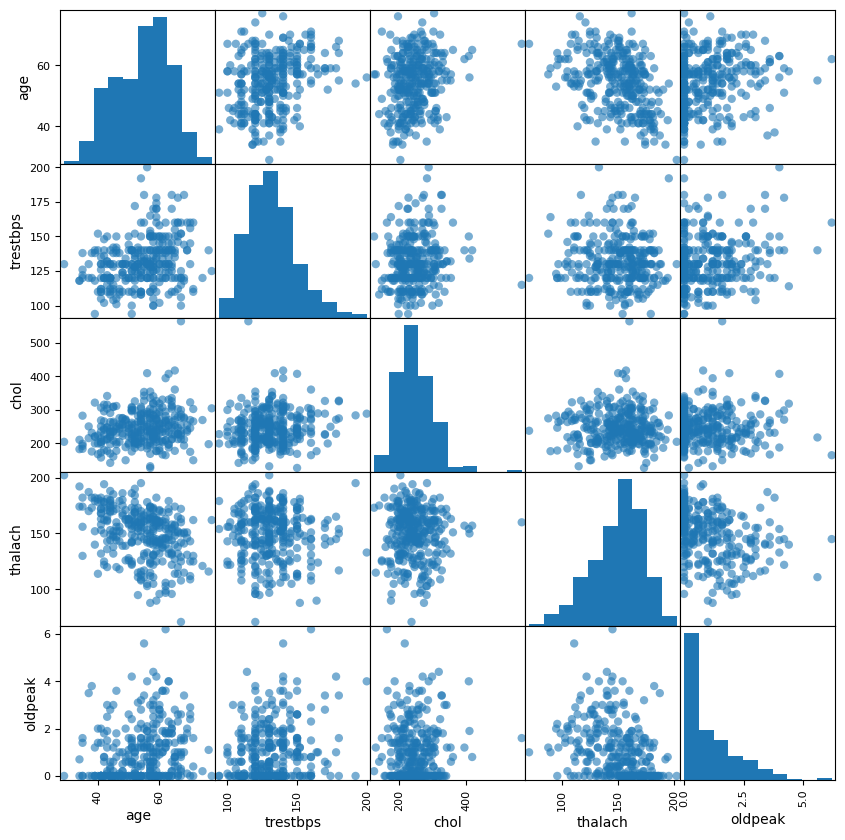

In [ ]:
print(raw.shape)

pd.plotting.scatter_matrix(
    raw[["age", "trestbps", "chol", "thalach", "oldpeak"]],
    figsize=(10, 10),
    marker="o",
    alpha=0.6,
)
plt.show()


In [ ]:
print(raw["sex"].value_counts())
print(raw["fbs"].value_counts())
print(raw["restecg"].value_counts())

sex
1    206
0     97
Name: count, dtype: int64
fbs
0    258
1     45
Name: count, dtype: int64
restecg
0    151
2    148
1      4
Name: count, dtype: int64


303 observations, 14 variables (13 potential predictor vars, 1 target var)

Aforementioned predictor vars (described, if necessary, according to official documentation):

* `age`,
* `sex`,
* `trestbps` (resting blood pressure, in mm Hg on admission),
* `chol` (serum cholestoral, in mg/dl),
* `fbs` (fasting blood sugar, > 120 mg/dl; 0 = false, 1 = true),
* `restecg` (resting electrocardiographic results: 0 = normal, 1 = abnormality,
2 = left ventricular hypertrophy),
* `thalach` (max. heart rate),
* and `oldpeak` (ST segment depression induced by exercise relative to rest).

Aforementioned target var:

* num (diagnosis: 0 = <50% diameter of any major vessel narrowing, 1 = >50% diameter narrowing)

None of the numerical predictor variables seem to have a high correlation with each other.

2. Determine whether your dataset contains missing values. If it does, explain how you handled them.

In [ ]:
raw[["age", "trestbps", "chol", "fbs", "restecg", "thalach", "oldpeak", "sex"]].isna().sum()

,0
age,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
oldpeak,0
sex,0


None of the relevant variables contains `na` values (target var `num` was checked afore).

3. Determine whether any categorical predictors need to be encoded before modeling.

In [ ]:
# convert categorical vars `fbs` and `restecg` to labels
processed["fbs"] = raw["fbs"].map({
    0: "low",
    1: "high"
})
processed["restecg"] = raw["restecg"].map({
    0: "normal",
    1: "abnormal",
    2: "left"
})
processed["sex"] = raw["sex"].map({
    0: "female",
    1: "male"
})

# one-hot encoding
one_hot = pd.get_dummies(processed[["fbs", "restecg", "sex"]], dtype = int)

# appending encoded vars to dataset; source: https://pandas.pydata.org/docs/reference/api/pandas.concat.html
processed = pd.concat([processed, one_hot], axis = 1)

features = ["age", "trestbps", "chol", "thalach", "oldpeak", "fbs_low", "fbs_high", "restecg_normal", "restecg_abnormal", "restecg_left", "sex_female", "sex_male"]

In [ ]:
print(
    processed.groupby("num")[["age", "trestbps", "chol", "thalach", "oldpeak"]].agg(
        ["mean", "std", "skew"]
    )
)

           age                        trestbps                       \
          mean       std      skew        mean        std      skew   
num                                                                   
0    52.585366  9.511957  0.116956  129.250000  16.204739  0.433387   
1    56.625899  7.938416 -0.558152  134.568345  18.769019  0.834327   

           chol                          thalach                       \
           mean        std      skew        mean        std      skew   
num                                                                     
0    242.640244  53.456580  1.755008  158.378049  19.199080 -0.698025   
1    251.474820  49.486835  0.299113  139.258993  22.593233 -0.309349   

      oldpeak                      
         mean       std      skew  
num                                
0    0.586585  0.781734  1.638980  
1    1.574101  1.302580  0.745543  



4. Divide the data. K-fold CV will be performed after fitting each model.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    processed[features],
    processed["num"],
    test_size = 0.25,
    random_state = 0,
)

5. Determine whether predictors should be standardized for any of the classifiers you will use.

Yes: `oldpeak` has significantly smaller values than the other four vars.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Part 3: Build Your Classifiers

Decision threshold: as aforementioned, this model should be optimized for minimal false negatives. Only patients under minimal danger should be deprioritized: thus, a decision threshold of 0.30 would be appropriate for this model.

In [ ]:
# logistic regression model
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
lr.fit(X_train_scaled, y_train)

# model's test probabilities and predictions
resultsLR = pd.DataFrame()
resultsLR["p(heart disease)"] = lr.predict_proba(X_test_scaled)[:, 1]
resultsLR["prediction"] = (lr.predict_proba(X_test_scaled)[:,1] >= 0.30).astype(int)
print(resultsLR.head())

c = {"logisticregression__C": np.logspace(-3, 3, 7)}

for i in ["accuracy", "recall", "roc_auc_ovr"]:
  gridLR = GridSearchCV(
      lr,
      c,
      cv = 10,
      scoring = i
  ).fit(X_train_scaled, y_train)

  print(
      f"highest {i}: {round(gridLR.best_score_, 4)}, at C = {gridLR.best_params_["logisticregression__C"]}"
  )

   p(heart disease)  prediction
0          0.022708           0
1          0.721691           1
2          0.656229           1
3          0.365696           1
4          0.317360           1
highest accuracy: 0.7674, at C = 0.01
highest recall: 0.6764, at C = 10.0
highest roc_auc_ovr: 0.8124, at C = 0.1


In [ ]:
# LDA model
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_scaled, y_train)

# model's test probabilities and predictions
resultsLDA = pd.DataFrame()
resultsLDA["p(heart disease)"] = lda.predict_proba(X_test_scaled)[:, 1]
resultsLDA["prediction"] = (lda.predict_proba(X_test_scaled)[:, 1] >= 0.30).astype(int)
print(resultsLDA.head())

for i in ["accuracy", "recall", "roc_auc_ovr"]:
  LDA_scores = cross_val_score(
      lda,
      X_train_scaled,
      y_train,
      cv = 10,
      scoring = i
  )
  print(
      f"\nmean {i}: {round(LDA_scores.mean(), 4)}"
      f"\nhighest {i}: {round(LDA_scores.max(), 4)}"
  )

   p(heart disease)  prediction
0          0.016330           0
1          0.670176           1
2          0.697317           1
3          0.280416           0
4          0.302775           1

mean accuracy: 0.7362
highest accuracy: 0.8261

mean recall: 0.6464
highest recall: 0.8182

mean roc_auc_ovr: 0.8099
highest roc_auc_ovr: 0.925


In [ ]:
# QDA model

# during testing of QDA model, encountered many repeated Python warnings: covariance matrices not in full rank, suggested to increase the value of `reg_param`: mean recall was 0.5355, whilst highest was 1.0, suggesting overfitting.
# looked through Scikit-Learn documentation of the parameter (https://sklearner.com/sklearn-quadraticdiscriminantanalysis-reg_param-parameter/)
# reg_param=1 yieled best recall rates without overfitting; ultimately kept at =0.001, to not complicate analysis
qda = QuadraticDiscriminantAnalysis(reg_param = 0.001)
qda.fit(X_train_scaled, y_train)

# model's test probabilities and predictions
resultsQDA = pd.DataFrame()
resultsQDA["p(heart disease)"] = qda.predict_proba(X_test_scaled)[:, 1]
resultsQDA["prediction"] = (qda.predict_proba(X_test_scaled)[:,1] >= 0.30).astype(int)
print(resultsQDA.head())

for i in ["accuracy", "recall", "roc_auc_ovr"]:
  QDA_scores = cross_val_score(
      qda,
      X_train_scaled,
      y_train,
      cv = 10,
      scoring = i
  )
  print(
      f"\nmean {i}: {round(QDA_scores.mean(), 4)}"
      f"\nhighest {i}: {round(QDA_scores.max(), 4)}"
  )

   p(heart disease)  prediction
0          0.001037           0
1          0.678486           1
2          0.845443           1
3          0.701935           1
4          0.192041           0

mean accuracy: 0.7283
highest accuracy: 0.9091

mean recall: 0.55
highest recall: 0.9

mean roc_auc_ovr: 0.792
highest roc_auc_ovr: 0.9583


In [ ]:
# choosing K-value
k_values = [1, 11, 21, 31]

cv_accuracy = []
cv_recall = []
cv_roc_auc = []

for k in k_values:
  for i in ["accuracy", "recall", "roc_auc_ovr"]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors = k)
    )
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv = 10,
        scoring = i
    )
    if (i == "accuracy"):
        cv_accuracy.append(scores.mean())
    elif (i == "recall"):
        cv_recall.append(scores.mean())
    else: cv_roc_auc.append(scores.mean())


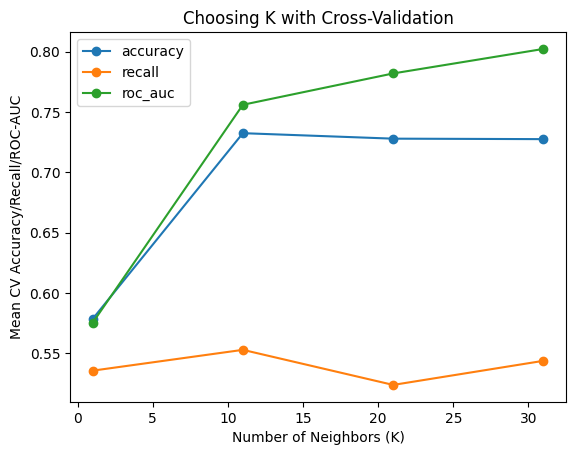

In [ ]:
plt.plot(
    k_values,
    cv_accuracy,
    marker="o",
    label = "accuracy"
)
plt.plot(
    k_values,
    cv_recall,
    marker="o",
    label = "recall"
)
plt.plot(
    k_values,
    cv_roc_auc,
    marker="o",
    label = "roc_auc"
)


plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean CV Accuracy/Recall/ROC-AUC")
plt.title("Choosing K with Cross-Validation")

plt.legend()
plt.show()


The KNN recall rate is highest at k=1, which is unideal.

In [ ]:
# choosing K-value
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

knn_tuning = {
    'kneighborsclassifier__n_neighbors': [3, 5, 9, 11, 13, 15, 17],
    'kneighborsclassifier__weights': ['uniform', 'distance']
}
for i in ["accuracy", "recall", "roc_auc_ovr"]:
  KNNgrid = GridSearchCV(
      knn,
      knn_tuning,
      cv = 10,
      scoring = i
  ).fit(X_train_scaled, y_train)
  print(
      f"highest {i}: {KNNgrid.best_score_}, {KNNgrid.best_params_}"
    )

highest accuracy: 0.7363636363636364, {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'uniform'}
highest recall: 0.6009090909090908, {'kneighborsclassifier__n_neighbors': 9, 'kneighborsclassifier__weights': 'distance'}
highest roc_auc_ovr: 0.7723688811188811, {'kneighborsclassifier__n_neighbors': 17, 'kneighborsclassifier__weights': 'uniform'}


Chosen classifier: LDA.

Logistic regression is the second optimal-most choice, especially because the numerical predictors are not normal.

QDA has high rates, but is the inferior choice to LDA, and only performs best when its boundary is reguralized.

KNN needs more data; using the current dataset, I do not feel confident using the KNN model, as it has showed high variance rates during training.

Part 4: Evaluate your models

In [ ]:
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=10.0)
).fit(X_train_scaled, y_train)

y_pred_lr = (lr.predict_proba(X_test_scaled)[:, 1] >= 0.30).astype(int)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

print(confusion_matrix(y_test, y_pred_lr),
      accuracy_score(y_test, y_pred_lr),
      precision_score(y_test, y_pred_lr),
      recall_score(y_test, y_pred_lr),
      f1_score(y_test, y_pred_lr),
      roc_auc_score(y_test, y_prob_lr))

[[24 16]
 [ 7 29]] 0.6973684210526315 0.6444444444444445 0.8055555555555556 0.7160493827160493 0.8097222222222221


Logistic regression:
* Accuracy: 0.6921
* Precision: 0.6445
* Recall: 0.8056
* Specificity: 24/(24+16) = 0.600
* F1: 0.7160
* ROC-AUC: 0.8097

In [ ]:
# LDA model evaluation
y_pred_lda = (lda.predict_proba(X_test_scaled)[:, 1] >= 0.30).astype(int)
y_prob_lda = lda.predict_proba(X_test_scaled)[:, 1]

print(confusion_matrix(y_test, y_pred_lda),
      accuracy_score(y_test, y_pred_lda),
      precision_score(y_test, y_pred_lda),
      recall_score(y_test, y_pred_lda),
      f1_score(y_test, y_pred_lda),
      roc_auc_score(y_test, y_prob_lda))

[[26 14]
 [ 7 29]] 0.7236842105263158 0.6744186046511628 0.8055555555555556 0.7341772151898734 0.8104166666666667


LDA:
* Accuracy: 0.7237
* Precision: 0.6744
* Recall: 0.8056
* Specificity: 0.650
* F1: 0.7342
* ROC-AUC: 0.8104

In [ ]:
# QDA model evaluation
y_pred_qda = (qda.predict_proba(X_test_scaled)[:, 1] >= 0.30).astype(int)
y_prob_qda = qda.predict_proba(X_test_scaled)[:, 1]

print(confusion_matrix(y_test, y_pred_qda),
      accuracy_score(y_test, y_pred_qda),
      precision_score(y_test, y_pred_qda),
      recall_score(y_test, y_pred_qda),
      f1_score(y_test, y_pred_qda),
      roc_auc_score(y_test, y_prob_qda))

[[29 11]
 [12 24]] 0.6973684210526315 0.6857142857142857 0.6666666666666666 0.676056338028169 0.8152777777777778


QDA:
* Accuracy: 0.6974
* Precision: 0.6857
* Recall: 0.6667
* Specificity: 0.725
* F1: 0.6761
* ROC-AUC: 0.8153

In [ ]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors = 9, weights = "distance"))
knn.fit(X_train_scaled, y_train)

y_pred_knn = (knn.predict_proba(X_test_scaled)[:, 1] >= 0.30).astype(int)
y_prob_knn = knn.predict_proba(X_test_scaled)[:, 1]

print(confusion_matrix(y_test, y_pred_knn),
      accuracy_score(y_test, y_pred_knn),
      precision_score(y_test, y_pred_knn),
      recall_score(y_test, y_pred_knn),
      f1_score(y_test, y_pred_knn),
      roc_auc_score(y_test, y_prob_knn))

[[22 18]
 [ 3 33]] 0.7236842105263158 0.6470588235294118 0.9166666666666666 0.7586206896551724 0.7909722222222222


KNN:
* Accuracy: 0.7237
* Precision: 0.6471
* Recall: 0.9167
* Specificity: 22/(22+18) = 0.5500
* F1: 0.7586
* ROC-AUC: 0.7910

Part 5: Reflect

For this dataset, the most important parameter is recall score, or how many patients with heart disease were correctly identified. However, considering the application of this model, it is not necessary, in my opinion, to fixate on the recall score so closely, as models are rarely permitted to make such important decisions by themselves. Given that this model considers already hospitalized patients, it would likely be used to adjust patient priority to improve treatment efficiency when clinical staff are under pressure.

Part 6: ROC and AUC

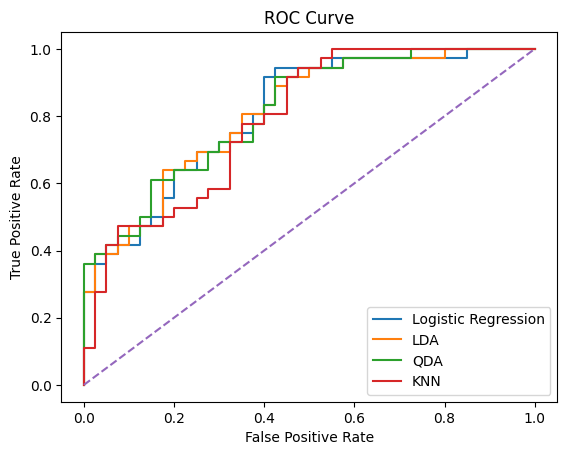

In [ ]:
z = 0;
for i in [y_prob_lr, y_prob_lda, y_prob_qda, y_prob_knn]:
  fpr, tpr, thresholds = roc_curve(
      y_test,
      i,
  )
  z = z + 1;
  if(z == 1):
    label = "Logistic Regression"
  elif(z == 2):
    label = "LDA"
  elif(z == 3):
    label = "QDA"
  else: label = "KNN"
  plt.plot(
      fpr,
      tpr,
      label = label
      )
z = 0;

plt.plot(
    [0, 1],
    [0, 1],
    linestyle = "--"
)
plt.legend()

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

The ROC-AUC curve shows how accurate models are across thresholds. In the context of this project, the four models have granulated curves due to the small size of the dataset, and their curves being similar suggests that all four models had similar performances across the board.

Part 7: Final Analysis

Presented above are the results of testing four different types of models to predict heart disease based on the medical record of patients. The results were pretty similar: only the QDA model struggled to identify patients with heart disease (a metric known as recall), as the distribution of several features such as blood pressure, cholesterol, and heart rate were skewed among patients. I focused on recall as the main metric, because in real-life scenarios, letting a sick patient go could have much more drastic consequences than keeping a healthy patient hospitalized longer.

For this specific dataset, I would suggest the LDA model. It had a promising recall score of 0.8056, second-highest ROC-AUC of 0.8104, and is usually perfect for training on smaller datasets. Logistic regression would be a good alternative.

Unfortunately, the dataset might have several flaws that could not be accounted for. For example, documentation implies that the target variable used to have more classes, suggesting that the current binary variable might not reveal enough information about patients' conditions. Furthermore, the original dataset apparently had >70 vars, whereas our dataset only had 14.

Ultimately, as a medical model, I struggle to believe it would have relevant applications in the real world without, at least, more data to improve its results. For now, however, LDA is probably your best bet for accurately guessing whether or not a patient has heart disease without having to expend critical resources.